In [1]:
from __future__ import annotations

import math
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

In [11]:
DATA_DIR_NAMES = [
     Path('upcoding_v28_top10_ha2025_export_anyfix_v260612'),
    # 'upcoding_v28_top10_ha2025_export',
]
DATA_ZIP_NAMES = [f'{name}.zip' for name in DATA_DIR_NAMES]
COEFF_NAME = 'cms_v28_cna_coefficients_export_features.csv'
SEARCH_ROOTS = []
for root in (
    Path.cwd(),
    Path.cwd() / 'data' / 'upcoding',
    Path.cwd().parent / 'data' / 'upcoding',
    Path('/content'),
    Path('/content/data/upcoding'),
):
    if root not in SEARCH_ROOTS and root.exists():
        SEARCH_ROOTS.append(root)

outputs_dir = Path('outputs')
outputs_dir.mkdir(parents=True, exist_ok=True)
OUT = outputs_dir / 'selection_panels_outputs'
FIG = OUT / 'figures'
DATA_OUT = OUT / 'data'
for p in (OUT, FIG, DATA_OUT):
    p.mkdir(parents=True, exist_ok=True)

In [12]:
TAU = 0.5
RHO = 0.5
RELATED_SCORE = 0.5
SIGNAL_MODERATION = 0.25
FLOOR = 0.03
ETA = 1e-6
K_POLICY = 25
SELECTION_PLOT_EASE_SCALE = 8.0
VERSION = 'v5'
LAMBDAS = np.array([1e-6, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0])

SIGNAL_MODERATED = ['hcc155', 'hcc280', 'hcc38', 'hcc93', 'hcc328', 'hcc226']
RELATED_EXTRA = ['hcc21', 'hcc23', 'hcc35', 'hcc62', 'hcc64', 'hcc264', 'hcc267', 'hcc327']
MANUAL_BLOCKS = [
    ('Diabetes model branch', ['hcc36', 'hcc37', 'hcc38']),
    ('Heart failure model branch', ['hcc224', 'hcc225', 'hcc226']),
    ('CKD model branch', ['hcc328', 'hcc329']),
    ('Substance-use model branch', ['hcc137', 'hcc138', 'hcc139']),
    ('Mental-health model branch', ['hcc151', 'hcc152', 'hcc153', 'hcc154', 'hcc155']),
    ('Vascular disease model branch', ['hcc263', 'hcc264', 'hcc267']),
    ('Cancer model branch', ['hcc20', 'hcc21', 'hcc22', 'hcc23']),
]

COL_SELECTED = '#1b9e77'
COL_CODING = '#2b6cb0'
COL_DROPPED = '#8c8c8c'
COL_HIGHLIGHT = '#d95f02'
GRID = '#d9d9d9'

plt.rcParams.update({
    'font.size': 8.5,
    'axes.titlesize': 9.5,
    'axes.labelsize': 8.8,
    'xtick.labelsize': 8.0,
    'ytick.labelsize': 8.0,
    'legend.fontsize': 7.5,
    'figure.titlesize': 9.5,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.spines.top': False,
    'axes.spines.right': False,
})


In [13]:
# Helper functions
def resolve_data_dir() -> Path:
    searched = []
    for root in SEARCH_ROOTS:
        for name in DATA_DIR_NAMES:
            candidate = root / name
            searched.append(str(candidate))
            if (candidate / 'baseline_hier.csv').exists():
                return candidate
    for root in SEARCH_ROOTS:
        for name in DATA_ZIP_NAMES:
            zip_path = root / name
            searched.append(str(zip_path))
            if zip_path.exists():
                work = OUT / '_unzipped'
                if work.exists():
                    shutil.rmtree(work)
                work.mkdir(parents=True, exist_ok=True)
                with zipfile.ZipFile(zip_path) as z:
                    z.extractall(work)
                for candidate in work.rglob('baseline_hier.csv'):
                    return candidate.parent
    raise FileNotFoundError(
        'Could not find the upcoding export folder or zip. Searched: ' + ', '.join(searched)
    )


def resolve_coeff_path() -> Path:
    searched = []
    for root in SEARCH_ROOTS:
        candidate = root / COEFF_NAME
        searched.append(str(candidate))
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        'Could not find the coefficient CSV. Searched: ' + ', '.join(searched)
    )


def parse_group_hccs(s) -> list[str]:
    if pd.isna(s):
        return []
    s = str(s).replace('HCC', 'hcc').replace(' ', '')
    return [p for p in s.split(',') if p.startswith('hcc')]


def get_target_rows(target_map: pd.DataFrame, features_all: list[str], coeff: pd.DataFrame) -> pd.DataFrame:
    rows = []
    if {'diagnosis_group', 'health_affairs_group_hccs', 'removal_effect_percent'}.issubset(target_map.columns):
        raw = target_map['removal_effect_percent'].astype(float).to_numpy()
        denom = float(np.nanmax(raw)) if np.nanmax(raw) > 0 else 1.0
        for _, r in target_map.iterrows():
            members = parse_group_hccs(r.get('health_affairs_group_hccs', ''))
            if not members:
                members = [str(r.get('target_hcc', r.get('hcc', '')))]
            rows.append({
                'diagnosis_group': str(r['diagnosis_group']),
                'members': members,
                'target_hcc': str(r.get('target_hcc', members[0] if members else '')),
                'score_raw': float(r['removal_effect_percent']),
                'score': float(r['removal_effect_percent']) / denom,
                'source': 'health-affairs-risk-contribution',
            })
        return pd.DataFrame(rows)
    if {'v22_label', 'hcc', 'ma_prev', 'tm_prev'}.issubset(target_map.columns):
        tmp = target_map.copy()
        tmp['lift_weight'] = tmp.get('lift_weight', 1.0)
        raw_scores = []
        for _, r in tmp.iterrows():
            h = str(r['hcc'])
            coef = float(coeff.loc[h, 'cna_coef']) if h in coeff.index else 1.0
            raw_scores.append(max(float(r['ma_prev']) - float(r['tm_prev']), 0.0) * float(r['lift_weight']) * abs(coef))
        denom = max(raw_scores) if max(raw_scores) > 0 else 1.0
        for raw, (_, r) in zip(raw_scores, tmp.iterrows()):
            h = str(r['hcc'])
            rows.append({
                'diagnosis_group': str(r['v22_label']),
                'members': [h],
                'target_hcc': h,
                'score_raw': raw,
                'score': raw / denom,
                'source': 'ma-tm-prevalence-lift-times-signal',
            })
        return pd.DataFrame(rows)
    raise ValueError('Unrecognized target mapping table format.')


def support_to_string(features: list[str], support) -> str:
    return '|'.join(features[i] for i in sorted(support))


def parse_support(s: object) -> set[str]:
    if pd.isna(s):
        return set()
    if isinstance(s, str):
        return {x for x in s.split('|') if x}
    return set(s)


In [14]:
class CaseStudyProblem:
    def __init__(self, data_dir: Path):
        self.data_dir = data_dir
        self.base = pd.read_csv(data_dir / 'baseline_hier.csv')
        self.target_map = pd.read_csv(data_dir / 'target_mapping_table.csv')
        self.coeff = pd.read_csv(resolve_coeff_path()).set_index('feature')
        self.features_all = [c for c in self.base.columns if c != 'person_id']

        X_all_raw = self.base[self.features_all].astype(float).values
        self.prev_all = X_all_raw.mean(axis=0)
        self.active_idx = np.where(self.prev_all > 0)[0]
        self.features = [self.features_all[i] for i in self.active_idx]
        self.d = len(self.features)

        theta_all = np.zeros(len(self.features_all))
        self.desc_map = {f: '' for f in self.features_all}
        for i, f in enumerate(self.features_all):
            if f in self.coeff.index:
                theta_all[i] = float(self.coeff.loc[f, 'cna_coef'])
                self.desc_map[f] = str(self.coeff.loc[f, 'description'])
        self.theta = theta_all[self.active_idx]

        X = X_all_raw[:, self.active_idx]
        self.X_centered = X - X.mean(axis=0)
        self.Sigma = (self.X_centered.T @ self.X_centered) / self.X_centered.shape[0]
        self.Sigma = (self.Sigma + self.Sigma.T) / 2
        self.bvec = self.Sigma @ self.theta
        signal = self.X_centered @ self.theta
        self.sigma2 = float(0.25 * np.var(signal))
        self._support_risk_cache = {}
        self.build_cost_matrix()

    def build_cost_matrix(self):
        target_rows = get_target_rows(self.target_map, self.features_all, self.coeff)
        D_raw_all = np.full(len(self.features_all), FLOOR)
        group_blocks = []
        self.top_members = set()
        self.top_group = {}
        self.top_score = {}

        for _, row in target_rows.iterrows():
            score = float(row['score'])
            members = [m for m in row['members'] if isinstance(m, str) and m in self.features_all]
            group_name = str(row['diagnosis_group'])
            if members:
                group_blocks.append((group_name, members))
            for f in members:
                j = self.features_all.index(f)
                D_raw_all[j] = max(D_raw_all[j], FLOOR + score)
                self.top_members.add(f)
                self.top_group[f] = group_name
                self.top_score[f] = score

        for f in RELATED_EXTRA:
            if f in self.features_all:
                j = self.features_all.index(f)
                D_raw_all[j] = max(D_raw_all[j], FLOOR + RELATED_SCORE)

        D_final_all = D_raw_all.copy()
        for f in SIGNAL_MODERATED:
            if f in self.features_all:
                j = self.features_all.index(f)
                D_final_all[j] = FLOOR + SIGNAL_MODERATION * (D_final_all[j] - FLOOR)

        block_defs = group_blocks + MANUAL_BLOCKS
        seen, block_defs_unique = set(), []
        for name, members in block_defs:
            key = tuple(sorted(members))
            if key in seen:
                continue
            seen.add(key)
            block_defs_unique.append((name, members))

        B_all = np.zeros((len(self.features_all), len(self.features_all)))
        for _, members in block_defs_unique:
            idx = [self.features_all.index(f) for f in members if f in self.features_all]
            if len(idx) >= 2:
                v = np.zeros(len(self.features_all))
                for j in idx:
                    v[j] = math.sqrt(max(D_final_all[j], FLOOR))
                B_all += np.outer(v, v)

        self.D_all = D_final_all
        self.B_all = B_all
        self.D = D_final_all[self.active_idx]
        self.B = B_all[np.ix_(self.active_idx, self.active_idx)]
        if np.max(np.diag(self.B)) > 0:
            self.B = self.B / np.max(np.diag(self.B))
        self.G = TAU * (np.diag(self.D) + RHO * self.B) + ETA * np.eye(self.d)
        self.H = np.linalg.inv(self.G)

        comp_rows = []
        for pos, f in enumerate(self.features):
            category = 'baseline floor'
            if f in RELATED_EXTRA and f not in self.top_members:
                category = 'pre-specified diagonal score'
            if f in self.top_members:
                category = 'coding-sensitive group score'
            if f in SIGNAL_MODERATED:
                category = 'signal-moderated top-ten groups'
            j = self.features_all.index(f)
            comp_rows.append({
                'feature': f,
                'description': self.desc_map.get(f, ''),
                'baseline_prevalence': float(self.prev_all[j]),
                'theta_star': float(self.theta[pos]),
                'abs_theta_star': abs(float(self.theta[pos])),
                'top10_group': self.top_group.get(f, ''),
                'coding_sensitive': f in self.top_members,
                'group_score': float(self.top_score.get(f, np.nan)) if f in self.top_score else np.nan,
                'D_final': float(self.D[pos]),
                'B_diag': float(self.B[pos, pos]),
                'Hinv_diag': float(self.G[pos, pos]),
                'category': category,
                'signal_moderated': f in SIGNAL_MODERATED,
                'related_diagonal': f in RELATED_EXTRA,
                'active': True,
            })
        self.component_df = pd.DataFrame(comp_rows)

    def support_beta(self, S, lam: float):
        beta = np.zeros(self.d)
        idx = np.array(sorted(set(S)), dtype=int)
        if len(idx) == 0:
            return beta
        A = self.Sigma[np.ix_(idx, idx)] + lam * np.eye(len(idx))
        rhs = self.Sigma[np.ix_(idx, np.arange(self.d))] @ self.theta
        beta[idx] = np.linalg.solve(A + 1e-10 * np.eye(len(idx)), rhs)
        return beta

    def support_mask(self, S) -> int:
        mask = 0
        for i in sorted(set(S)):
            mask |= 1 << int(i)
        return mask

    def support_from_mask(self, mask: int) -> tuple[int, ...]:
        return tuple(i for i in range(self.d) if mask & (1 << i))

    def support_risk(self, S, lam: float, alpha: float = 1.0) -> float:
        mask = self.support_mask(S)
        key = (mask, float(lam), float(alpha))
        val = self._support_risk_cache.get(key)
        if val is not None:
            return val
        beta = self.support_beta(self.support_from_mask(mask), lam)
        val = self.mse(beta, alpha)
        self._support_risk_cache[key] = val
        return val

    def mse(self, beta, alpha: float = 1.0):
        diff = beta - self.theta
        pred = float(diff @ self.Sigma @ diff)
        q = float(beta @ self.G @ beta)
        return pred + (alpha * q) ** 2 + self.sigma2

    def swap_local_exact_k(self, S0, lam: float, k: int, alpha: float = 1.0, max_iter: int = 100):
        S = set(S0)
        if len(S) != k:
            raise ValueError('Initial support must have exact cardinality k')
        cur = self.support_risk(S, lam, alpha)
        for _ in range(max_iter):
            best, move = cur, None
            for i in list(S):
                base = S - {i}
                for j in range(self.d):
                    if j in S:
                        continue
                    val = self.support_risk(base | {j}, lam, alpha)
                    if val < best - 1e-12:
                        best, move = val, (i, j)
            if move is None:
                break
            S.remove(move[0])
            S.add(move[1])
            cur = best
        beta = self.support_beta(S, lam)
        val = self.mse(beta, alpha)
        return {'mse': val, 'risk': val, 'lambda': float(lam), 'beta': beta, 'support': tuple(sorted(S))}

    def greedy_exact_k(self, k: int, lam: float, alpha: float = 1.0):
        S = set()
        while len(S) < k:
            best, best_j = None, None
            for j in range(self.d):
                if j in S:
                    continue
                val = self.support_risk(S | {j}, lam, alpha)
                if best is None or val < best:
                    best, best_j = val, j
            S.add(best_j)
        return self.swap_local_exact_k(S, lam, k, alpha)

    def tune_exact_k(self, k: int, alpha: float = 1.0):
        best = None
        for lam in LAMBDAS:
            rec = self.greedy_exact_k(k, lam, alpha)
            if best is None or rec['mse'] < best['mse']:
                best = rec
        return best


def compute_required_supports(problem: CaseStudyProblem, k_values=(20, 25)) -> pd.DataFrame:
    rows = []
    for k in sorted(set(k_values)):
        if k > problem.d:
            continue
        rec = problem.tune_exact_k(k, alpha=1.0)
        rows.append({
            'k': k,
            'risk': float(rec['risk']),
            'mse': float(rec['mse']),
            'lambda': float(rec['lambda']),
            'support': support_to_string(problem.features, rec['support']),
        })
    rows.append({
        'k': problem.d,
        'risk': float(problem.mse(problem.support_beta(tuple(range(problem.d)), 1e-6), 1.0)),
        'mse': float(problem.mse(problem.support_beta(tuple(range(problem.d)), 1e-6), 1.0)),
        'lambda': 1e-6,
        'support': support_to_string(problem.features, tuple(range(problem.d))),
    })
    return pd.DataFrame(rows).drop_duplicates('k').sort_values('k')


def build_selection_data(problem: CaseStudyProblem, support_df: pd.DataFrame):
    support_by_k = {int(row['k']): parse_support(row['support']) for _, row in support_df.iterrows()}
    active = problem.component_df.copy()
    active['coding_sensitive'] = active['top10_group'].fillna('').astype(str).ne('')
    active['selected_k20'] = active['feature'].isin(support_by_k.get(20, set()))
    active['selected_k25'] = active['feature'].isin(support_by_k.get(25, set()))
    active['selected_k30'] = active['feature'].isin(support_by_k.get(problem.d, set(active['feature'])))
    active['signal_abs'] = active['theta_star'].abs()
    active['Hinv_diag_display'] = active['Hinv_diag'] * SELECTION_PLOT_EASE_SCALE
    active['feature_upper'] = active['feature'].str.upper()
    active.to_csv(DATA_OUT / 'active_feature_signal_manipulability_selection.csv', index=False)

    short_label = {
        'hcc38': 'Diabetes (HCC38)',
        'hcc93': 'Rheumatoid arthritis (HCC93)',
        'hcc155': 'Depression (HCC155)',
        'hcc226': 'Heart failure (HCC226)',
        'hcc280': 'COPD/lung (HCC280)',
        'hcc328': 'CKD stage 3B (HCC328)',
    }
    coding = active[active['coding_sensitive']].copy()
    coding = coding.sort_values('theta_star', ascending=False).reset_index(drop=True)
    coding['label'] = coding['feature'].map(short_label).fillna(coding['feature'].str.upper())
    coding.to_csv(DATA_OUT / 'coding_sensitive_active_hccs.csv', index=False)

    cols_main = [
        ('Exclusion', 'Top-ten exclusion', lambda f: 0),
        ('Ours k=20', r'Ours $k=20$', lambda f: int(f in support_by_k.get(20, set()))),
        ('Ours k=25', r'Ours $k=25$', lambda f: int(f in support_by_k.get(25, set()))),
        ('Full ridge', 'Full ridge', lambda f: 1),
    ]
    ret_mat = np.array([[fn(f) for _, _, fn in cols_main] for f in coding['feature']], dtype=float)
    ret_summary = ret_mat.mean(axis=0, keepdims=True)
    plot_mat = np.vstack([ret_mat, ret_summary])
    row_labels = coding['label'].tolist() + ['Fraction retained']
    col_labels = [lab for _, lab, _ in cols_main]

    ret_records = []
    for i, rowlab in enumerate(row_labels):
        for j, collab in enumerate(col_labels):
            ret_records.append({'row': rowlab.replace('\n', ' '), 'column': collab.replace('\n', ' '), 'value': plot_mat[i, j]})
    pd.DataFrame(ret_records).to_csv(DATA_OUT / 'coding_sensitive_retention_main_matrix.csv', index=False)
    return active, coding, plot_mat, row_labels, col_labels


def plot_retention_panel_custom(plot_mat, row_labels, col_labels, version=VERSION):
    fig_a, ax = plt.subplots(figsize=(3.65, 2.72))
    ax.imshow(plot_mat, vmin=0, vmax=1, aspect='auto', cmap='Greens')
    ax.set_xticks(np.arange(len(col_labels)))
    wrapped_col_labels = [c.replace(' ', '\n', 1) for c in col_labels]
    ax.set_xticklabels(wrapped_col_labels)
    ax.set_yticks(np.arange(len(row_labels)))
    ax.set_yticklabels(row_labels)
    ax.set_title('HCC retention (1 = kept)', loc='center', pad=3, fontsize=9.6)
    ax.set_xticks(np.arange(-0.5, len(col_labels), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(row_labels), 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=1.2)
    ax.tick_params(which='minor', bottom=False, left=False)
    ax.hlines(len(row_labels) - 1.5, -0.5, len(col_labels) - 0.5, color='black', linewidth=0.8)
    for i in range(plot_mat.shape[0]):
        for j in range(plot_mat.shape[1]):
            val = plot_mat[i, j]
            text = f'{val:.2f}' if i == plot_mat.shape[0] - 1 else ('1' if val >= 0.5 else '0')
            color = 'white' if val >= 0.7 else 'black'
            weight = 'bold' if i == plot_mat.shape[0] - 1 else 'normal'
            ax.text(j, i, text, ha='center', va='center', fontsize=8.0, color=color, fontweight=weight)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig_a.tight_layout(pad=0.55)
    fig_a.savefig(FIG / f'hcc_retention_panel_a.png', dpi=300, bbox_inches='tight')
    fig_a.savefig(FIG / f'hcc_retention_panel_a.pdf', dpi=300, bbox_inches='tight')
    plt.close(fig_a)


def plot_signal_vs_manip_custom(active, version=VERSION):
    fig_b, ax = plt.subplots(figsize=(3.65, 2.72))

    mask = (~active['coding_sensitive']) & (active['selected_k25'])
    ax.scatter(active.loc[mask, 'Hinv_diag_display'], active.loc[mask, 'signal_abs'], s=25, marker='o', color=COL_SELECTED, alpha=0.78, edgecolor='white', linewidth=0.35, label='Selected')

    mask = (~active['coding_sensitive']) & (~active['selected_k25'])
    ax.scatter(active.loc[mask, 'Hinv_diag_display'], active.loc[mask, 'signal_abs'], s=34, marker='x', color=COL_DROPPED, linewidth=1.15, label='Dropped')

    mask = active['coding_sensitive'] & active['selected_k25']
    ax.scatter(active.loc[mask, 'Hinv_diag_display'], active.loc[mask, 'signal_abs'], s=44, marker='D', color=COL_CODING, alpha=0.95, edgecolor='black', linewidth=0.45, label='Top-ten diagnosis groups')

    mask = active['coding_sensitive'] & (~active['selected_k25'])
    if mask.any():
        ax.scatter(active.loc[mask, 'Hinv_diag_display'], active.loc[mask, 'signal_abs'], s=46, marker='D', color=COL_HIGHLIGHT, alpha=0.95, edgecolor='black', linewidth=0.45, label='Coding-sensitive dropped')

    label_features = ['hcc38', 'hcc93', 'hcc155', 'hcc226', 'hcc280', 'hcc328']
    offsets = {
        'hcc93': (5, 5),
        'hcc155': (5, -9),
        'hcc38': (5, -8),
        'hcc226': (5, 6),
        'hcc280': (5, -2),
        'hcc328': (5, 5),
    }
    scatter_label = {
        'hcc38': 'Diabetes',
        'hcc93': 'RA',
        'hcc155': 'Depression',
        'hcc226': 'HF',
        'hcc280': 'COPD',
        'hcc328': 'CKD3B',
    }
    for _, r in active[active['feature'].isin(label_features)].iterrows():
        dx, dy = offsets.get(r['feature'], (4, 4))
        ax.annotate(scatter_label.get(r['feature'], r['feature_upper']),
                    xy=(r['Hinv_diag_display'], r['signal_abs']),
                    xytext=(dx, dy), textcoords='offset points',
                    fontsize=7.0, ha='left', va='center')

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'Manipulation ease $H^{-1}_{jj}$', fontsize=9.6)
    ax.set_ylabel(r'Published coefficient $|\theta^*_j|$', fontsize=9.6)
    ax.set_title(r'Signal vs. manipulation ease ($k=25$)', loc='center', pad=3, fontsize=9.6)
    ax.grid(True, which='both', linewidth=0.45, color=GRID, alpha=0.65)
    ax.legend(loc='upper right', frameon=True, framealpha=0.94, borderpad=0.30, handletextpad=0.35, labelspacing=0.30)
    fig_b.tight_layout(pad=0.55)
    fig_b.savefig(FIG / f'signal_vs_manipulability_panel_b.png', dpi=300, bbox_inches='tight')
    fig_b.savefig(FIG / f'signal_vs_manipulability_panel_b.pdf', dpi=300, bbox_inches='tight')
    plt.close(fig_b)


def main():
    data_dir = resolve_data_dir()
    resolve_coeff_path()
    problem = CaseStudyProblem(data_dir)
    support_df = compute_required_supports(problem, k_values=(20, K_POLICY))
    support_df.to_csv(DATA_OUT / 'exact_k_supports_needed_for_selection_panels.csv', index=False)
    active, coding, plot_mat, row_labels, col_labels = build_selection_data(problem, support_df)
    plot_retention_panel_custom(plot_mat, row_labels, col_labels, version=VERSION)
    plot_signal_vs_manip_custom(active, version=VERSION)
    print('Wrote:')
    print(FIG / f'hcc_retention_panel_a.pdf')
    print(FIG / f'hcc_retention_panel_a.png')
    print(FIG / f'signal_vs_manipulability_panel_b.pdf')
    print(FIG / f'signal_vs_manipulability_panel_b.png')
    print(DATA_OUT / 'active_feature_signal_manipulability_selection.csv')
    print(DATA_OUT / 'exact_k_supports_needed_for_selection_panels.csv')


if __name__ == '__main__':
    main()


Wrote:
outputs/selection_panels_outputs/figures/hcc_retention_panel_a.pdf
outputs/selection_panels_outputs/figures/hcc_retention_panel_a.png
outputs/selection_panels_outputs/figures/signal_vs_manipulability_panel_b.pdf
outputs/selection_panels_outputs/figures/signal_vs_manipulability_panel_b.png
outputs/selection_panels_outputs/data/active_feature_signal_manipulability_selection.csv
outputs/selection_panels_outputs/data/exact_k_supports_needed_for_selection_panels.csv


outputs/selection_panels_outputs/figures/hcc_retention_panel_a.png


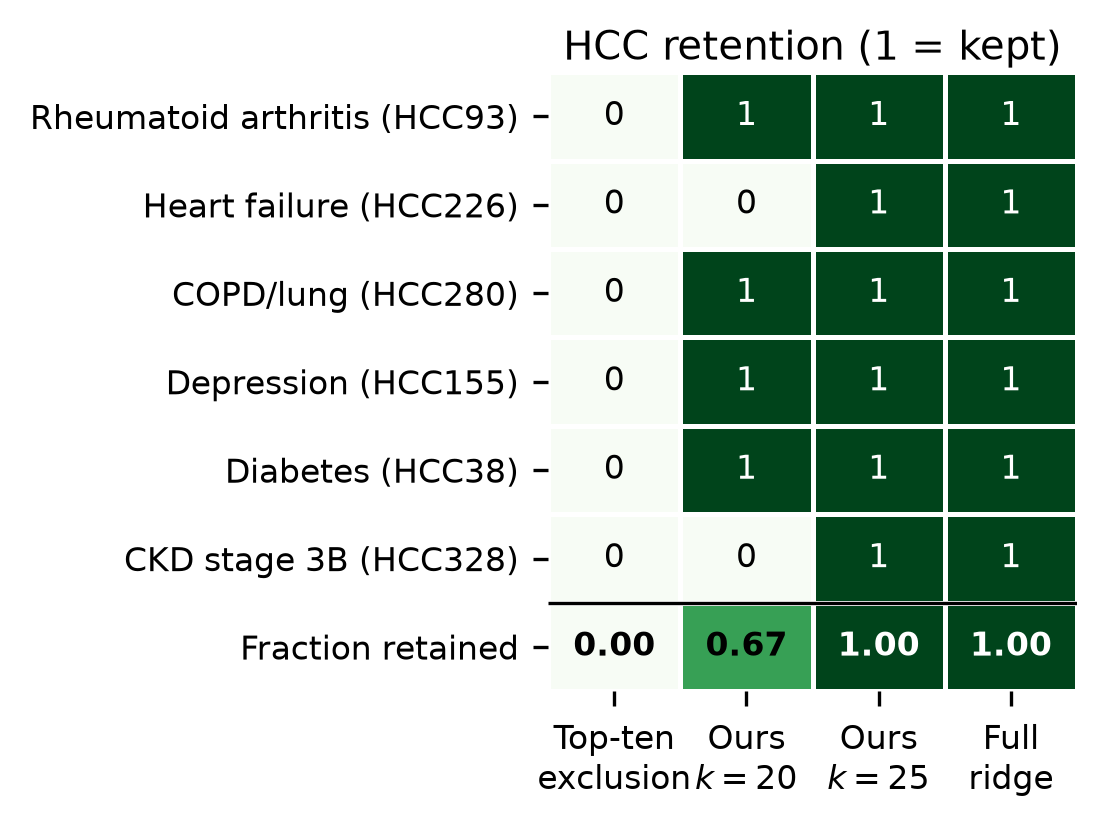

outputs/selection_panels_outputs/figures/signal_vs_manipulability_panel_b.png


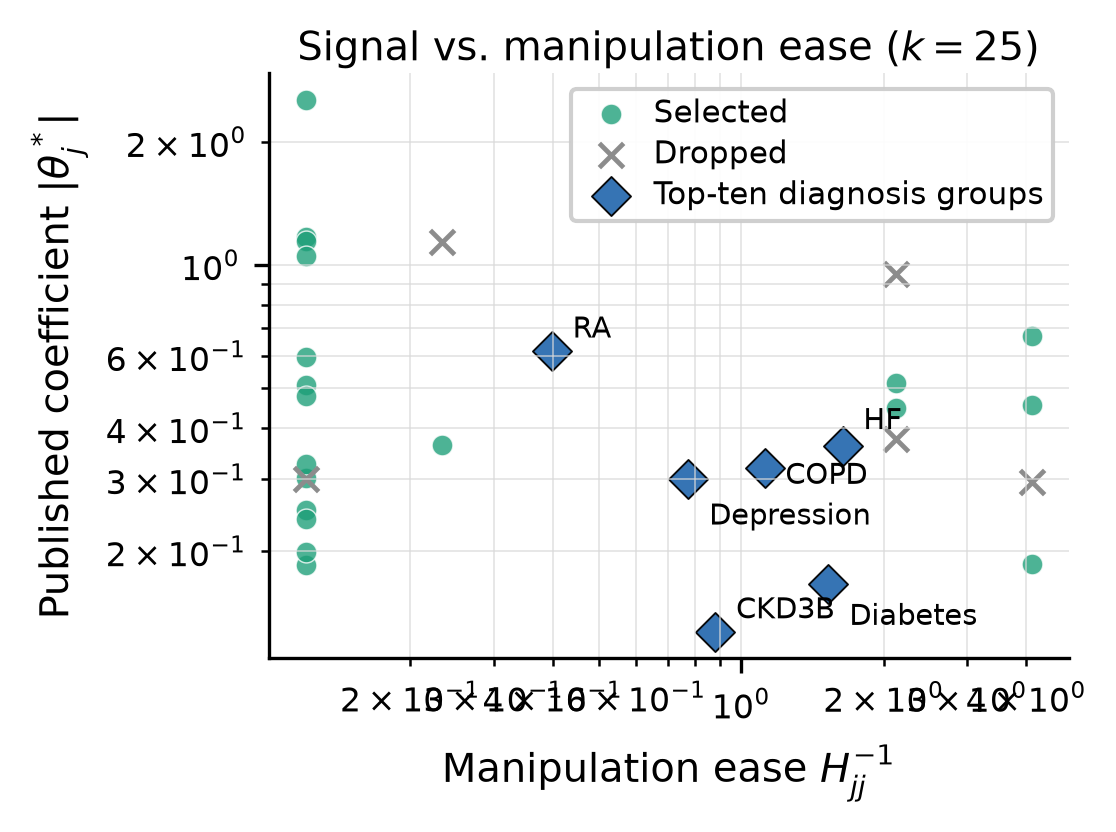

In [15]:
from IPython.display import Image, display

for fig_path in [
    'outputs/selection_panels_outputs/figures/hcc_retention_panel_a.png',
    'outputs/selection_panels_outputs/figures/signal_vs_manipulability_panel_b.png',
]:
    print(fig_path)
    display(Image(filename=fig_path))
